In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/city_day.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [58]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (29531, 16)

Missing Values:


,Missing Count
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854



Duplicate Rows: 0


In [59]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nAQI Statistics:")
display(df["AQI"].describe())

Column Names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data Types:
City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str
dtype: object

AQI Statistics:


count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64

In [60]:
df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["City", "Date", "AQI"]
)

df_clean = df_clean.drop_duplicates(
    subset=["City", "Date"]
)

df_clean = df_clean.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

print("Original Rows:", len(df))
print("Clean Rows:", len(df_clean))

Original Rows: 29531
Clean Rows: 24850


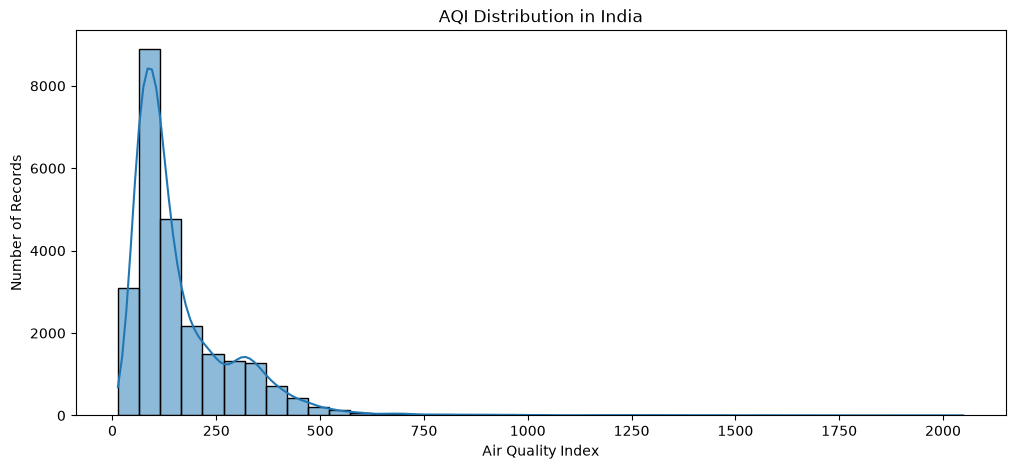

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_clean,
    x="AQI",
    bins=40,
    kde=True
)

plt.title("AQI Distribution in India")
plt.xlabel("Air Quality Index")
plt.ylabel("Number of Records")
plt.show()

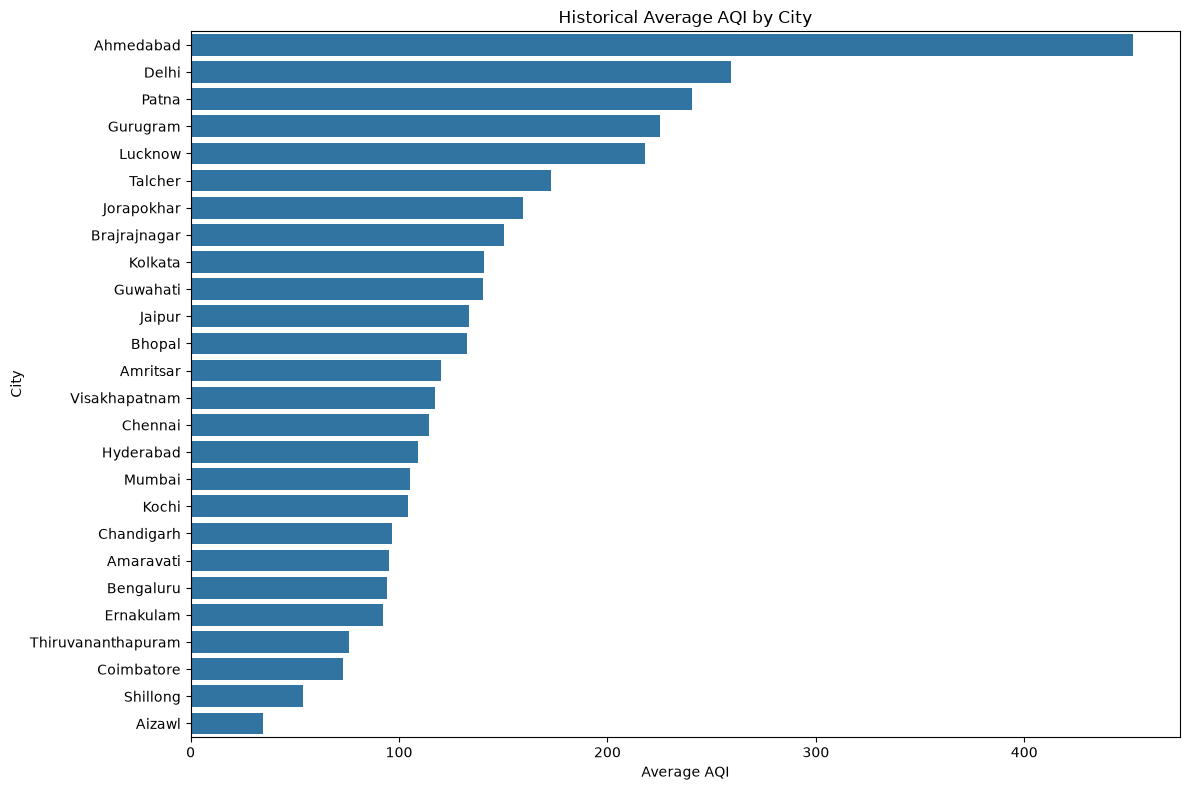

In [62]:
city_avg = (
    df_clean.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=city_avg.values,
    y=city_avg.index
)

plt.title("Historical Average AQI by City")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [63]:
df_clean["Next_Day_AQI"] = (
    df_clean.groupby("City")["AQI"].shift(-1)
)

df_clean["Next_Date"] = (
    df_clean.groupby("City")["Date"].shift(-1)
)

# Sirf actual consecutive dates rakho
df_model = df_clean[
    (df_clean["Next_Date"] - df_clean["Date"]).dt.days == 1
].copy()

df_model = df_model.dropna(subset=["Next_Day_AQI"])

print("Training-ready rows:", len(df_model))

display(
    df_model[
        ["City", "Date", "AQI", "Next_Date", "Next_Day_AQI"]
    ].head(10)
)

Training-ready rows: 24343


,City,Date,AQI,Next_Date,Next_Day_AQI
0,Ahmedabad,2015-01-29,209.0,2015-01-30,328.0
1,Ahmedabad,2015-01-30,328.0,2015-01-31,514.0
2,Ahmedabad,2015-01-31,514.0,2015-02-01,782.0
3,Ahmedabad,2015-02-01,782.0,2015-02-02,914.0
4,Ahmedabad,2015-02-02,914.0,2015-02-03,660.0
5,Ahmedabad,2015-02-03,660.0,2015-02-04,294.0
6,Ahmedabad,2015-02-04,294.0,2015-02-05,149.0
7,Ahmedabad,2015-02-05,149.0,2015-02-06,190.0
8,Ahmedabad,2015-02-06,190.0,2015-02-07,247.0
9,Ahmedabad,2015-02-07,247.0,2015-02-08,379.0


In [64]:
features = [
    "AQI",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

features = [col for col in features if col in df_model.columns]

X = df_model[features].copy()
y = df_model["Next_Day_AQI"].copy()

print("Selected Features:", features)
print("Total Records:", len(X))

Selected Features: ['AQI', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Total Records: 24343


In [65]:
df_model = df_model.sort_values("Date").reset_index(drop=True)

split_index = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_index]
test_df = df_model.iloc[split_index:]

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df["Next_Day_AQI"]
y_test = test_df["Next_Day_AQI"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("Train end:", train_df["Date"].max())
print("Test start:", test_df["Date"].min())

Training: (19474, 13)
Testing: (4869, 13)
Train end: 2019-12-07 00:00:00
Test start: 2019-12-07 00:00:00


In [66]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [67]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np

results = []
trained_models = {}

for name, pipeline in models.items():

    print("Training:", name)

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON RESULTS")
display(results_df.sort_values("MAE"))

print("\nresults_df created successfully!")


Training: Linear Regression
Training: Decision Tree
Training: Random Forest

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,R2 Score
2,Random Forest,17.982248,35.034583,0.848659
1,Decision Tree,19.769933,41.466400,0.787990
0,Linear Regression,21.802423,38.028173,0.821691



results_df created successfully!


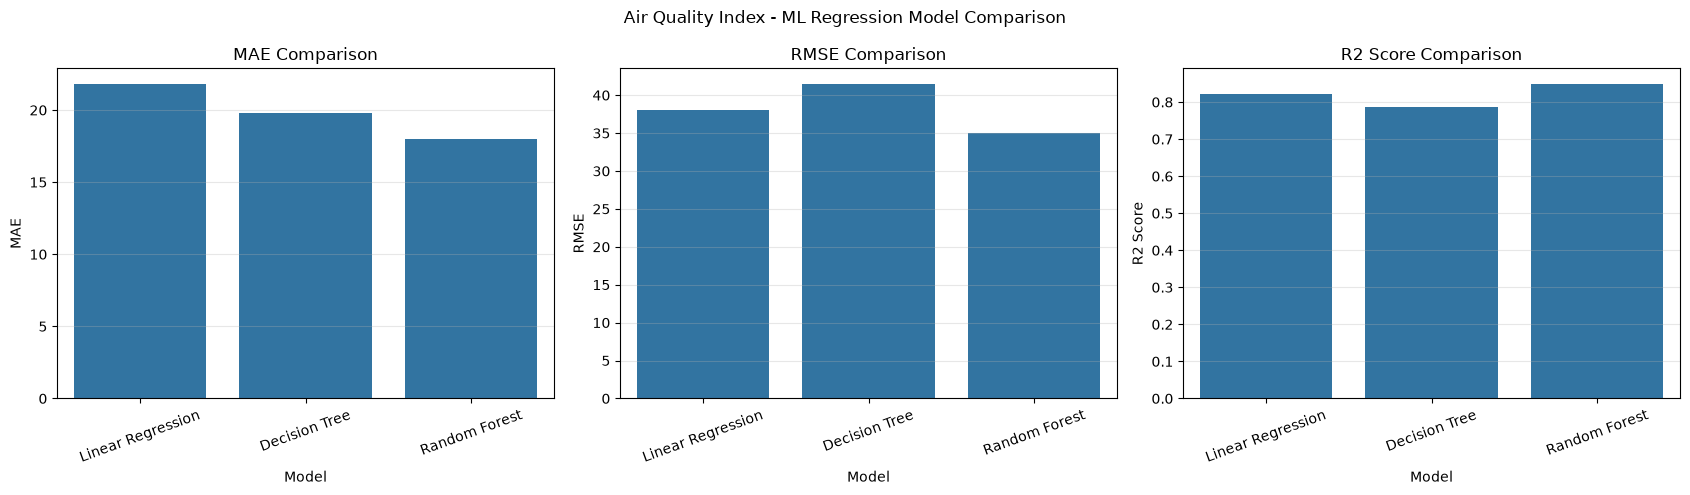

In [68]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(
    axes,
    ["MAE", "RMSE", "R2 Score"]
):
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(metric + " Comparison")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Air Quality Index - ML Regression Model Comparison"
)

plt.tight_layout()

plt.savefig(
    "AQI_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [69]:
best_model_name = results_df.sort_values(
    "MAE"
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


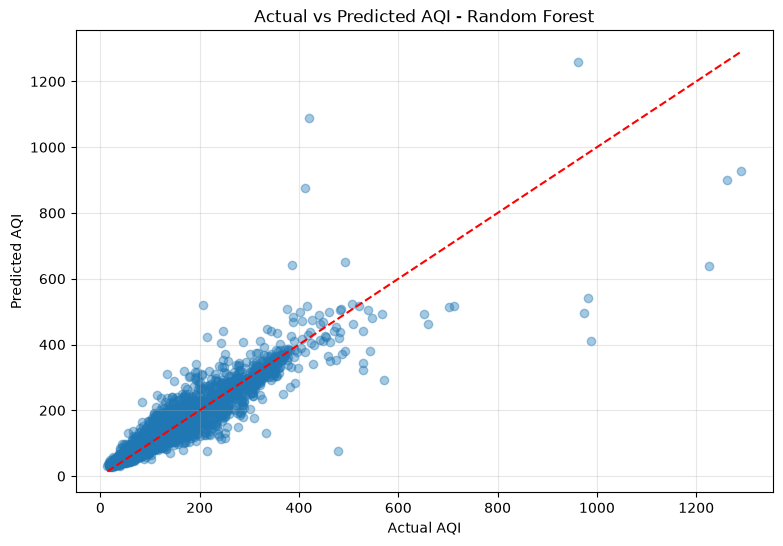

In [70]:
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title(f"Actual vs Predicted AQI - {best_model_name}")

plt.grid(alpha=0.3)
plt.show()

In [71]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "features": features,
        "model_name": best_model_name
    },
    model_dir / "best_aqi_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [72]:
baseline_pred = X_test["AQI"].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

model_mae = mean_absolute_error(
    y_test,
    y_pred
)

print("Baseline MAE:", round(baseline_mae, 2))
print("ML Model MAE:", round(model_mae, 2))

if model_mae < baseline_mae:
    print("ML model performs better than baseline.")
else:
    print("Baseline performs as well as or better than ML.")

Baseline MAE: 20.88
ML Model MAE: 17.98
ML model performs better than baseline.


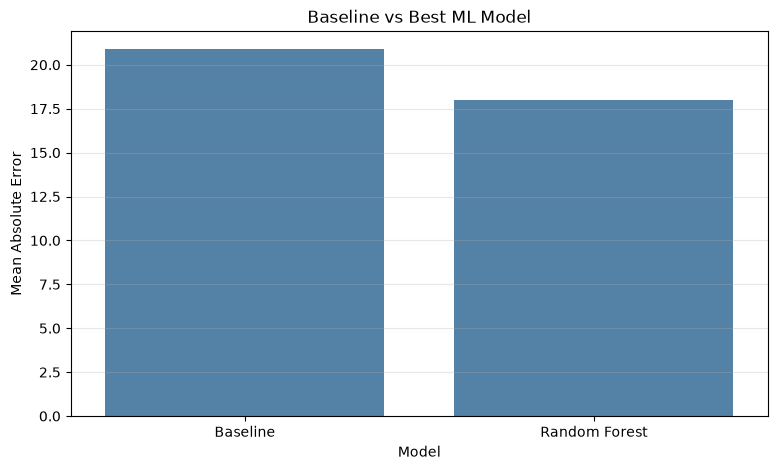

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

baseline_results = pd.DataFrame({
    "Model": ["Baseline", best_model_name],
    "MAE": [baseline_mae, model_mae]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=baseline_results,
    x="Model",
    y="MAE",
    color="steelblue"
)

plt.title("Baseline vs Best ML Model")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)

plt.savefig("Baseline_vs_ML.png", dpi=300, bbox_inches="tight")
plt.show()

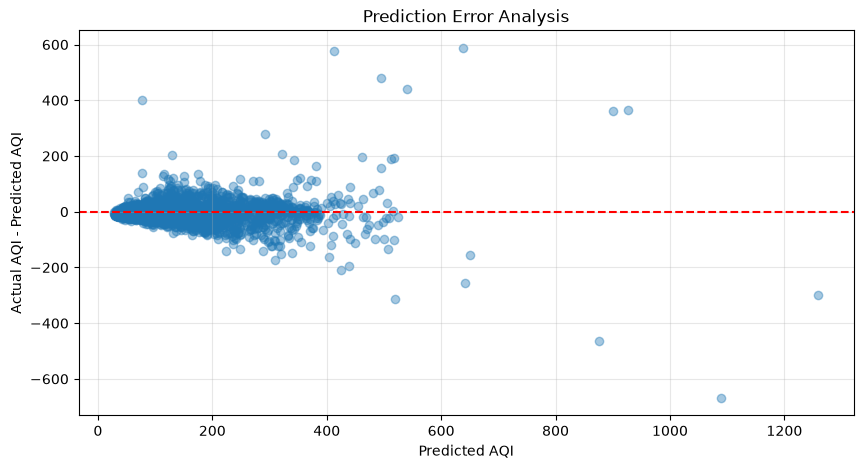

In [74]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(10, 5))

plt.scatter(y_pred, residuals, alpha=0.4)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Prediction Error Analysis")
plt.xlabel("Predicted AQI")
plt.ylabel("Actual AQI - Predicted AQI")
plt.grid(alpha=0.3)

plt.savefig("Prediction_Error.png", dpi=300, bbox_inches="tight")
plt.show()

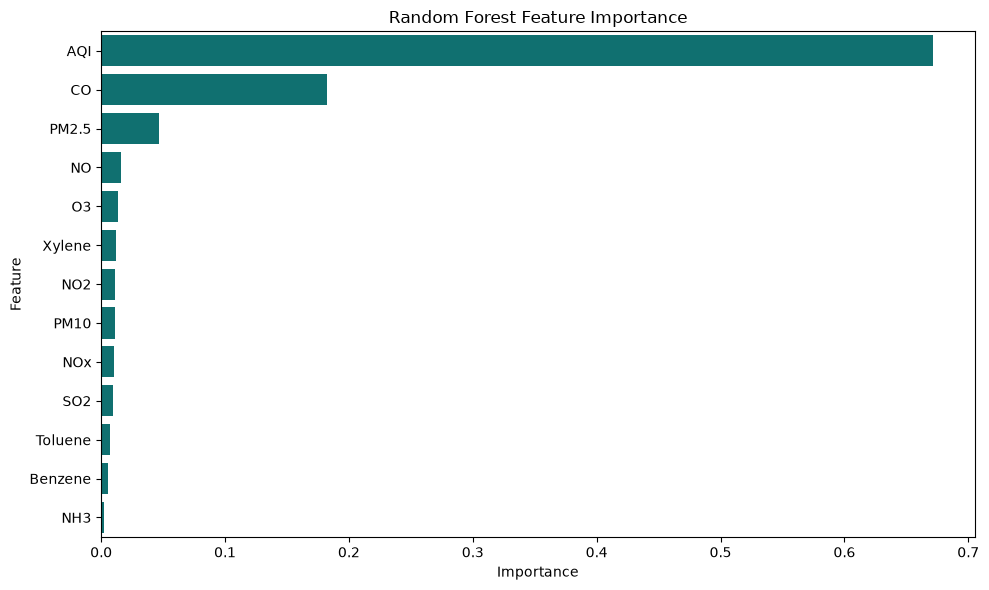

In [75]:
rf_pipeline = trained_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig("Feature_Importance.png", dpi=300, bbox_inches="tight")
plt.show()

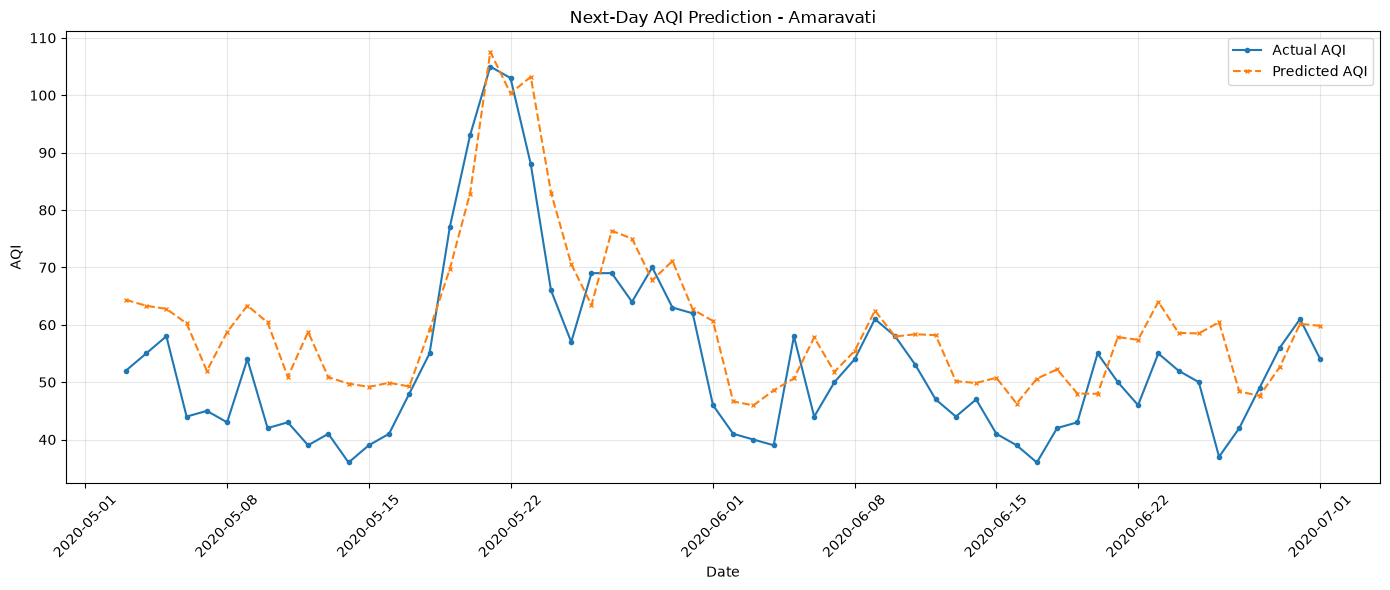

In [76]:
comparison_df = test_df[
    ["City", "Next_Date", "Next_Day_AQI"]
].copy()

comparison_df["Predicted_AQI"] = y_pred

city_name = comparison_df["City"].value_counts().idxmax()

city_data = (
    comparison_df[comparison_df["City"] == city_name]
    .sort_values("Next_Date")
    .tail(60)
)

plt.figure(figsize=(14, 6))

plt.plot(
    city_data["Next_Date"],
    city_data["Next_Day_AQI"],
    label="Actual AQI",
    marker="o",
    markersize=3
)

plt.plot(
    city_data["Next_Date"],
    city_data["Predicted_AQI"],
    label="Predicted AQI",
    linestyle="--",
    marker="x",
    markersize=3
)

plt.title(f"Next-Day AQI Prediction - {city_name}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Date_Wise_AQI.png", dpi=300, bbox_inches="tight")
plt.show()

In [77]:
import os

print("Saved Graphs:")
for file in os.listdir():
    if file.endswith(".png"):
        print(file)

Saved Graphs:
Actual_vs_Predicted.png
AQI_Model_Comparison.png
Baseline_vs_ML.png
Date_Wise_AQI.png
Feature_Importance.png
Model_Comparison.png
Prediction_Error.png


In [78]:
from pathlib import Path

model_path = Path(
    r"C:\Users\LALIT\OneDrive\Desktop\Air Quality Index\models\best_aqi_model.pkl"
)

print("Model exists:", model_path.exists())

Model exists: True


In [79]:

required = [
    "X_test",
    "y_test",
    "best_model",
    "trained_models",
    "features",
    "best_model_name"
]

for name in required:
    if name in globals():
        print(f"{name}: Available")
    else:
        print(f"{name}: Missing")


X_test: Available
y_test: Available
best_model: Available
trained_models: Available
features: Available
best_model_name: Available


In [80]:

import json
from pathlib import Path
import numpy as np

# 1. Actual and predicted AQI
actual = np.asarray(y_test, dtype=float).ravel()
predicted = np.asarray(
    best_model.predict(X_test),
    dtype=float
).ravel()

if len(actual) != len(predicted):
    raise ValueError("Actual and predicted lengths differ.")

# 2. Select up to 150 real test samples
indices = np.linspace(
    0,
    len(actual) - 1,
    min(150, len(actual)),
    dtype=int
)

comparison = [
    {
        "actual": round(float(actual[i]), 2),
        "predicted": round(float(predicted[i]), 2)
    }
    for i in indices
    if np.isfinite(actual[i]) and np.isfinite(predicted[i])
]

# 3. Random Forest feature importance
rf_pipeline = trained_models["Random Forest"]

rf_model = (
    rf_pipeline.named_steps["model"]
    if hasattr(rf_pipeline, "named_steps")
    else rf_pipeline
)

feature_names = list(features)

if len(feature_names) != len(rf_model.feature_importances_):
    raise ValueError("Feature names and importance lengths differ.")

importance = [
    {
        "feature": str(name),
        "importance": round(float(value), 6)
    }
    for name, value in zip(
        feature_names,
        rf_model.feature_importances_
    )
]

importance.sort(
    key=lambda item: item["importance"],
    reverse=True
)

# 4. Find project directory
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

output_dir = project_dir / "static" / "data"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "model_evaluation.json"

# 5. Save JSON
with open(output_file, "w", encoding="utf-8") as file:
    json.dump(
        {
            "model": str(best_model_name),
            "comparison": comparison,
            "importance": importance
        },
        file,
        indent=2
    )

print("SUCCESS: Evaluation JSON created!")
print("File:", output_file.resolve())
print("Actual vs Predicted points:", len(comparison))
print("Feature Importance values:", len(importance))


SUCCESS: Evaluation JSON created!
File: C:\Users\LALIT\OneDrive\Desktop\Air Quality Index\static\data\model_evaluation.json
Actual vs Predicted points: 150
Feature Importance values: 13
